# 08 Trading Evaluation

用已保存预测回测 t 日信号、t+1 开盘建仓、t+2 开盘结算；对比模型、买入持有和 Double DQN。单边成本 5 bps，未计滑点和利息。


In [1]:
import json, hashlib, platform, sys
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, balanced_accuracy_score, accuracy_score, f1_score, r2_score
ROOT = Path.cwd().resolve()
assert (ROOT / '01_data_preprocessing.ipynb').is_file()
FEATURES = ['return_1d','return_5d','return_20d','volatility_20d','intraday_return','intraday_range']

def read_frame(path):
    f = pd.read_csv(path, index_col='signal_date', float_precision='round_trip')
    f.index = pd.to_datetime(f.index)
    for c in ['trade_date','settle_date']:
        if c in f: f[c] = pd.to_datetime(f[c])
    assert f.index.is_unique and f.index.is_monotonic_increasing
    return f

def write_json(path, obj):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def new_output(name):
    out = ROOT / 'output' / 'fusion' / name / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
    out.mkdir(parents=True)
    write_json(out/'environment.json', {'python':sys.version,'executable':sys.executable,'numpy':np.__version__,'pandas':pd.__version__})
    inputs = list((ROOT/'data/features').glob('*.csv')) + list((ROOT/'data/processed').glob('*.csv'))
    write_json(out/'fingerprints.json', {str(f.relative_to(ROOT)):hashlib.sha256(f.read_bytes()).hexdigest() for f in inputs})
    return out

def complete_run(name):
    runs = [p for p in (ROOT/'output'/name).iterdir() if (p/'status.json').exists() and json.loads((p/'status.json').read_text())['status']=='completed']
    return sorted(runs)[-1]

def training_folder(run, arm):
    return sorted((run/arm).glob('train_*'))[-1]

def regression_scores(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return {'n':len(y),'mae_bp':np.mean(abs(y-p))*10000,'rmse_bp':np.sqrt(np.mean((y-p)**2))*10000,
            'r2':r2_score(y,p) if len(y)>1 and np.var(y)>0 else np.nan,'direction_accuracy':np.mean((y>0)==(p>0))}


In [2]:
OUT=new_output('08_trading')
MLP_DIR = ROOT/json.loads((ROOT/'output/fusion/mlp_latest.json').read_text())['path']
REG_RUN = ROOT/json.loads((MLP_DIR/'config.json').read_text())['source_run']
CLS_RUN = complete_run('classification_comparison')
SAMPLES = {t:read_frame(ROOT/f'data/features/{t}_samples.csv') for t in ['classification','regression']}
PRED = {}; THRESHOLDS = {}; META = {}
for name,run,arm,task in [('Class A',CLS_RUN,'baseline','classification'),('Class B',CLS_RUN,'final','classification'),('Regression XGB',REG_RUN,'baseline','regression'),('Ridge',REG_RUN,'final','regression')]:
    train=training_folder(run,arm)
    selected=json.loads((train/'selected.json').read_text())
    PRED[name]={s:read_frame(train/f'{s}_predictions.csv') for s in ['train','val']}
    PRED[name]['test']=read_frame(run/arm/'test_predictions.csv')
    THRESHOLDS[name]=selected.get('threshold',.002)  # Use the saved validation threshold
    META[name]={'task':task,'train_mean':selected['train_mean'],'train_median':selected['train_median'],'source_run':str(run.relative_to(ROOT))}
    for s,f in PRED[name].items():
        sample=SAMPLES[task].loc[f.index]
        for col in ['trade_date','settle_date']: pd.testing.assert_series_equal(f[col],sample[col])
        f['target_return']=sample.target_return
        f['target_class']=sample.target_class.astype(int)
        assert (f.index<f.trade_date).all() and (f.trade_date<f.settle_date).all()
PRED['MLP']={s:read_frame(MLP_DIR/f'{s}_predictions.csv') for s in ['train','val','test']}
THRESHOLDS['MLP']=.002
META['MLP']={**META['Ridge'],'source_run':str(MLP_DIR.relative_to(ROOT))}
prices=pd.read_csv(ROOT/'data/processed/sp500_clean.csv',parse_dates=['date']).set_index('date')
for name,parts in PRED.items():
    for s,f in parts.items():
        expected=prices.open.reindex(f.settle_date).to_numpy()/prices.open.reindex(f.trade_date).to_numpy()-1
        np.testing.assert_allclose(f.target_return,expected,atol=1e-14)  # Check target alignment against original opens
def backtest(frame, positions, fee=.0005):
    f=frame[['trade_date','settle_date','target_return']].copy()
    p=np.asarray(positions,dtype=float)
    assert len(f)==len(p) and np.isin(p,[0,1]).all()
    previous=np.r_[0,p[:-1]]
    # On a gap, settle the prior position and start from cash.
    gaps=np.r_[False, f.trade_date.iloc[1:].to_numpy()!=f.settle_date.iloc[:-1].to_numpy()]
    exit_before=np.zeros(len(f)); exit_before[np.flatnonzero(gaps)-1]=p[np.flatnonzero(gaps)-1]
    previous[gaps]=0  # Reset positions when dates are discontinuous
    turnover=abs(p-previous)
    exit_after=exit_before.copy(); exit_after[-1]=p[-1]
    net=(1-fee*turnover)*(1+p*f.target_return.to_numpy())*(1-fee*exit_after)-1  # Charge entry and exit before compounding
    f['position']=p; f['entry_turnover']=turnover;f['exit_turnover']=exit_after
    f['turnover']=turnover+exit_after; f['add_day']=(p>previous).astype(int)
    f['net_return']=net;f['equity']=np.cumprod(1+net)
    f['drawdown']=f.equity/np.maximum.accumulate(np.r_[1,f.equity])[1:]-1
    return f

def trading_scores(h):
    r=h.net_return; std=r.std(ddof=1)
    return {'n':len(h),'total_return':np.prod(1+r)-1,'max_drawdown':-h.drawdown.min(),
            'sharpe':np.sqrt(252)*r.mean()/std if len(h)>1 and std>0 else np.nan,
            'trades':int((h.entry_turnover>0).sum()+(h.exit_turnover>0).sum()),'turnover':h.turnover.sum(),
            'add_day_fraction':h.add_day.mean(),'holding_time_fraction':(h.position>0).mean(),'average_position':h.position.mean()}


### Double DQN

训练期拟合标准化器，验证期选下跌惩罚；三个种子投票，测试期冻结。


In [3]:
import torch
from torch import nn
from copy import deepcopy
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
SEEDS=(42,43,44); UPDATES=1800; GAMMA=.95**(1/5); FEE=.0005
DDQN_FEATURES=['return_5','return_20','return_60','trend_50','trend_200','volatility_20','drawdown_63']
market=pd.DataFrame(index=prices.index)
existing=read_frame(ROOT/'data/features/sp500_features.csv')
for n in [5,20]: market[f'return_{n}']=existing[f'return_{n}d'].reindex(market.index)
market['return_60']=prices.close.pct_change(60)
for n in [50,200]: market[f'trend_{n}']=prices.close/prices.close.rolling(n).mean()-1
market['volatility_20']=existing['volatility_20d'].reindex(market.index)
market['drawdown_63']=prices.close/prices.close.rolling(63).max()-1
# All features are known at signal-day close. No extra shift is needed here.
blocks={s:f.join(market).dropna(subset=DDQN_FEATURES) for s,f in PRED['Ridge'].items()}
scaler=StandardScaler().fit(blocks['train'][DDQN_FEATURES])  # Fit DDQN scaling on train only

def make_network():
    return nn.Sequential(nn.Linear(8,32),nn.ReLU(),nn.Linear(32,32),nn.ReLU(),nn.Linear(32,2))

def train_ddqn(seed,downside):
    torch.manual_seed(seed);rng=np.random.default_rng(seed)
    net=make_network();target=deepcopy(net).eval()
    opt=torch.optim.AdamW(net.parameters(),lr=.001,weight_decay=.003)
    f=blocks['train']; x=np.repeat(scaler.transform(f[DDQN_FEATURES]),2,axis=0)
    positions=np.tile([0,1],len(f)); actions=np.array([0,1])
    states=torch.tensor(np.column_stack([x,positions]),dtype=torch.float32)
    gross=1+np.repeat(f.target_return.to_numpy(),2)[:,None]*actions
    costs=1-FEE*abs(positions[:,None]-actions)
    # Last transition includes liquidation, matching evaluation.
    gross[-2:]*=(1-FEE*actions)  # Include the final liquidation cost in reward
    logs=np.log(gross*costs)
    reward=torch.tensor(100*(logs+downside*np.minimum(logs,0)),dtype=torch.float32)
    next_rows=np.minimum(np.arange(len(f))+1,len(f)-1)
    next_ids=torch.tensor(2*np.repeat(next_rows,2)[:,None]+actions)
    mask=torch.ones((2*len(f),1));mask[-2:]=0
    for update in range(UPDATES):
        batch=rng.integers(len(states),size=128)
        with torch.no_grad():
            ns=states[next_ids[batch]]
            act=net(ns).argmax(-1,keepdim=True)
            future=target(ns).gather(-1,act).squeeze(-1)
            desired=reward[batch]+GAMMA*mask[batch]*future  # Compute a bootstrapped Double DQN target
        loss=nn.functional.smooth_l1_loss(net(states[batch]),desired)
        opt.zero_grad();loss.backward();nn.utils.clip_grad_norm_(net.parameters(),10);opt.step()
        if (update+1)%100==0:target.load_state_dict(net.state_dict())
    return net.eval()

def policy_path(models,frame):
    x=np.repeat(scaler.transform(frame[DDQN_FEATURES]),2,axis=0)
    states=torch.tensor(np.column_stack([x,np.tile([0,1],len(frame))]),dtype=torch.float32)
    with torch.no_grad(): choices=np.stack([m(states).reshape(-1,2,2).argmax(-1).numpy() for m in models])
    prior=0; path=[]
    for i in range(len(frame)):
        # Every voter sees the same incoming position of this actual path.
        pos=int(choices[:,i,prior].sum()>len(models)//2)
        path.append(pos);prior=pos
    return np.asarray(path)

search=[]; fitted={}
for downside in [0.,.25,.5]:
    models=[train_ddqn(seed,downside) for seed in SEEDS]
    h=backtest(blocks['val'],policy_path(models,blocks['val']))
    search.append({'downside':downside,**trading_scores(h)})
    fitted[downside]=models
    print('DDQN validation',downside,trading_scores(h)['sharpe'],flush=True)
selection=max(search,key=lambda r: r['sharpe'] if np.isfinite(r['sharpe']) else -np.inf)['downside']  # Select downside penalty by validation Sharpe
models=fitted[selection]
pd.DataFrame(search).to_csv(OUT/'ddqn_validation_search.csv',index=False)
joblib.dump(scaler,OUT/'ddqn_scaler.joblib')
for seed,m in zip(SEEDS,models):
    torch.save(m.state_dict(),OUT/f'ddqn_{seed}.pt')
    restored=make_network();restored.load_state_dict(torch.load(OUT/f'ddqn_{seed}.pt',weights_only=True));restored.eval()
    np.testing.assert_array_equal(policy_path([m],blocks['test']),policy_path([restored],blocks['test']))
write_json(OUT/'ddqn_config.json',{'source':'material2/SP500.ipynb cell19-20','seeds':SEEDS,'updates':UPDATES,'batch':128,'network':[8,32,32,2],'optimizer':'AdamW','lr':.001,'weight_decay':.003,'target_update':100,'gradient_clip':10,'loss':'smooth_l1','gamma':GAMMA,'fee':FEE,'downside_candidates':[0,.25,.5],'selected_downside':selection,'selection':'validation vote Sharpe','features':DDQN_FEATURES,'reload_actions_exact':True})


DDQN validation 0.0 0.6564642904028953
DDQN validation 0.25 1.0525616302550693
DDQN validation 0.5 0.7895653668005922


,n,total_return,max_drawdown,sharpe,trades,turnover,add_day_fraction,holding_time_fraction,average_position
seed,,,,,,,,,
42,752,0.584907,0.110724,1.467486,76,76.0,0.050532,0.309840,0.309840
43,752,0.932416,0.055329,2.202173,74,74.0,0.049202,0.413564,0.413564
44,752,1.146342,0.160244,2.126223,84,84.0,0.055851,0.533245,0.533245


,n,total_return,max_drawdown,sharpe,trades,turnover,add_day_fraction,holding_time_fraction,average_position
mean,752.0,0.887888,0.108766,1.931961,78.000000,78.000000,0.051862,0.418883,0.418883
std,0.0,0.283354,0.052485,0.404035,5.291503,5.291503,0.003518,0.111797,0.111797


,strategy,first_signal,last_signal,n,total_return,max_drawdown,sharpe,trades,turnover,add_day_fraction,holding_time_fraction,average_position
0,Class A,2025-01-29,2026-11-10,449,0.098988,0.168718,0.435717,112,112.0,0.124722,0.496659,0.496659
1,Class B,2025-01-29,2026-11-10,449,0.217912,0.166826,0.820976,124,124.0,0.138085,0.583519,0.583519
2,Regression XGB,2023-11-10,2026-11-10,752,0.077039,0.000500,0.575136,2,2.0,0.001330,0.001330,0.001330
3,Regression XGB val threshold,2023-11-10,2026-11-10,752,0.660280,0.192470,1.236688,6,6.0,0.003989,0.988032,0.988032
4,Ridge,2023-11-10,2026-11-10,752,0.061241,0.064402,0.339062,6,6.0,0.003989,0.005319,0.005319
5,Ridge val threshold,2023-11-10,2026-11-10,752,0.061241,0.064402,0.339062,6,6.0,0.003989,0.005319,0.005319
6,MLP,2023-11-10,2026-11-10,752,0.247889,0.000500,1.289499,20,20.0,0.013298,0.013298,0.013298
7,MLP val threshold,2023-11-10,2026-11-10,752,0.140235,0.000500,0.853059,6,6.0,0.003989,0.003989,0.003989
8,Buy hold,2023-11-10,2026-11-10,752,0.711793,0.192470,1.294864,2,2.0,0.001330,1.000000,1.000000
9,DDQN seed 42,2023-11-10,2026-11-10,752,0.584907,0.110724,1.467486,76,76.0,0.050532,0.309840,0.309840


cost_bps,0,3,5,10,20
strategy,,,,,
Buy hold,0.713506,0.712478,0.711793,0.710081,0.706659
Class A,0.162303,0.123893,0.098988,0.039093,-0.071162
Class B,0.295833,0.248507,0.217912,0.144642,0.010965
DDQN seed 42,0.646308,0.609191,0.584907,0.525767,0.413944
DDQN seed 43,1.005273,0.961240,0.932416,0.862172,0.729154
DDQN seed 44,1.238431,1.182720,1.146342,1.057997,0.891948
DDQN vote,1.010785,0.961916,0.929990,0.852404,0.706357
MLP,0.260433,0.252892,0.247889,0.235463,0.210963
MLP val threshold,0.143662,0.141605,0.140235,0.136817,0.130007


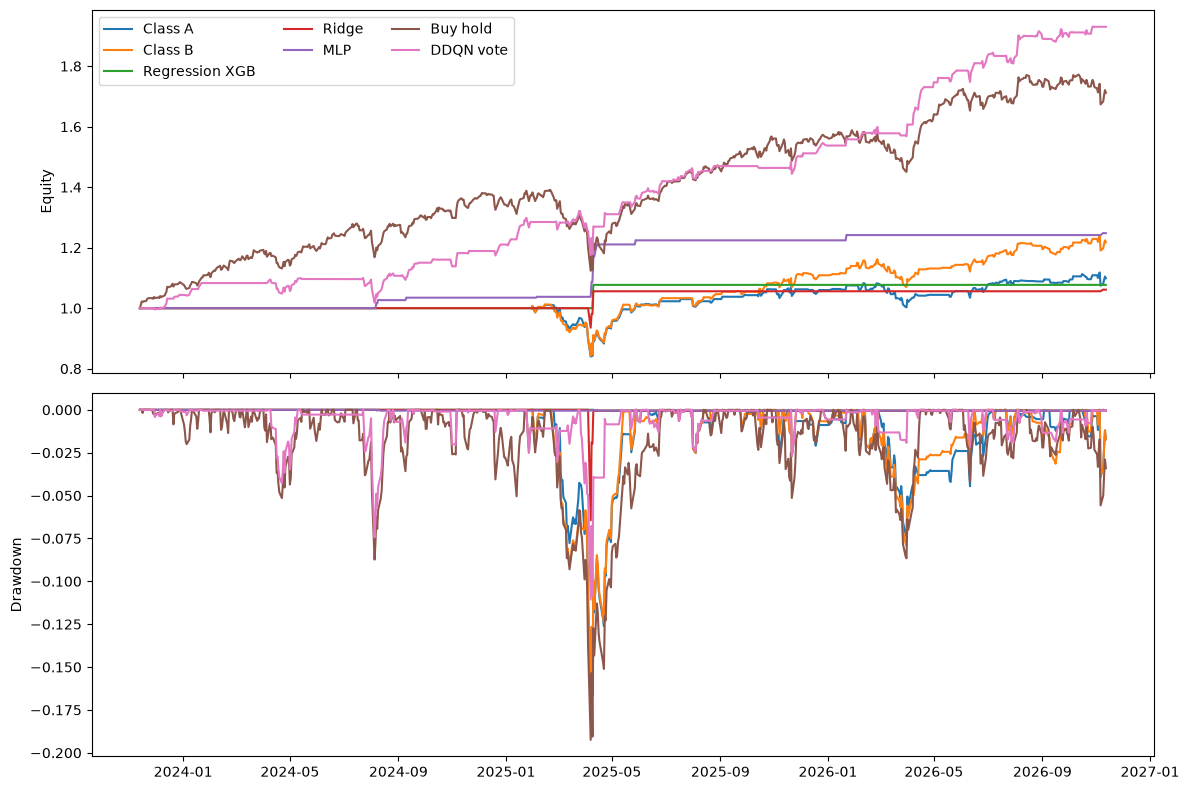

In [4]:
HIST={}; seed_rows=[]; threshold_rows=[]
for name,parts in PRED.items():
    f=parts['test']; task=META[name]['task']; th=THRESHOLDS[name]
    pos=(f.prediction>=th).astype(int) if task=='classification' else (f.prediction>th).astype(int)
    HIST[name]=backtest(f,pos)
    if task=='regression':
        val=parts['val']; candidates=[-.002,-.001,0,.001,.002,.003,.005]
        scores=[trading_scores(backtest(val,(val.prediction>t).astype(int)))['sharpe'] for t in candidates]
        chosen=candidates[max(range(len(scores)),key=lambda i:scores[i] if np.isfinite(scores[i]) else -np.inf)]
        HIST[name+' val threshold']=backtest(f,(f.prediction>chosen).astype(int))
        threshold_rows.extend([{'model':name,'threshold':t,'val_sharpe':v,'selected':t==chosen} for t,v in zip(candidates,scores)])
HIST['Buy hold']=backtest(PRED['Ridge']['test'],np.ones(len(PRED['Ridge']['test'])))
for seed,m in zip(SEEDS,models):
    h=backtest(blocks['test'],policy_path([m],blocks['test']))
    HIST[f'DDQN seed {seed}']=h;seed_rows.append({'seed':seed,**trading_scores(h)})
HIST['DDQN vote']=backtest(blocks['test'],policy_path(models,blocks['test']))  # Vote on positions from three saved seeds
seed_table=pd.DataFrame(seed_rows).set_index('seed');display(seed_table)
seed_summary=seed_table.agg(['mean','std']);display(seed_summary)
seed_table.to_csv(OUT/'ddqn_seed_metrics.csv');seed_summary.to_csv(OUT/'ddqn_seed_mean_std.csv')
pd.DataFrame(threshold_rows).to_csv(OUT/'regression_threshold_search.csv',index=False)
rows=[]; sensitivity=[]
for name,h in HIST.items():
    h.to_csv(OUT/(name.replace(' ','_')+'.csv'))
    rows.append({'strategy':name,'first_signal':h.index.min(),'last_signal':h.index.max(),**trading_scores(h)})
    for bps in [0,3,5,10,20]:
        sensitivity.append({'strategy':name,'cost_bps':bps,**trading_scores(backtest(h,h.position,bps/10000))})
table=pd.DataFrame(rows);table.to_csv(OUT/'trading_metrics.csv',index=False);display(table)
sens=pd.DataFrame(sensitivity);sens.to_csv(OUT/'cost_sensitivity.csv',index=False)
display(sens.pivot(index='strategy',columns='cost_bps',values='total_return'))
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True)
for name,h in HIST.items():
    if 'seed' in name or 'val threshold' in name:continue
    axes[0].plot([h.trade_date.iloc[0],*h.settle_date],[1,*h.equity],label=name)
    axes[1].plot([h.trade_date.iloc[0],*h.settle_date],[0,*h.drawdown],label=name)
axes[0].legend(ncol=3);axes[0].set_ylabel('Equity');axes[1].set_ylabel('Drawdown')
fig.tight_layout();fig.savefig(OUT/'equity_drawdown.png');display(fig);plt.close(fig)


### Prediction metrics

只评价产生预测的模型；成本敏感性固定原仓位路径。


In [5]:
prediction_rows=[]
for name,parts in PRED.items():
    f=parts['test'];y=f.target_return;p=f.prediction
    if META[name]['task']=='classification':
        label=f.target_class
        scores={'n':len(f),'roc_auc':roc_auc_score(label,p),'ap':average_precision_score(label,p),
                'accuracy':accuracy_score(label,p>=THRESHOLDS[name]),'balanced_accuracy':balanced_accuracy_score(label,p>=THRESHOLDS[name]),'f1':f1_score(label,p>=THRESHOLDS[name],zero_division=0)}
    else:scores=regression_scores(y,p)
    prediction_rows.append({'model':name,'task':META[name]['task'],**scores})
pd.DataFrame(prediction_rows).to_csv(OUT/'prediction_metrics.csv',index=False);display(pd.DataFrame(prediction_rows))
write_json(OUT/'sources.json',{'classification':str(CLS_RUN.relative_to(ROOT)),'regression':str(REG_RUN.relative_to(ROOT)),'mlp':str(MLP_DIR.relative_to(ROOT))})
write_json(ROOT/'output/fusion/trading_latest.json',{'path':str(OUT.relative_to(ROOT))})
# Cost and initial-equity checks.
example=PRED['Ridge']['test'].iloc[:2]
h=backtest(example,[1,1],.0005)
np.testing.assert_allclose(h.equity.iloc[-1],(.9995**2)*np.prod(1+example.target_return))
assert h.turnover.sum()==2
loss_example=example.copy();loss_example['target_return']=[-.1,0]
assert backtest(loss_example,[1,1],0).drawdown.min()<=-.099999
assert all(h.index.is_unique for h in HIST.values())
write_json(OUT/'verification.json',{'return_alignment':True,'initial_and_final_cost':True,'initial_equity_in_drawdown':True,'MLP_reload':True,'DDQN_reload':True,'seeds':SEEDS,'test_selection':False})
print('Saved:',OUT.relative_to(ROOT))


,model,task,n,roc_auc,ap,accuracy,balanced_accuracy,f1,mae_bp,rmse_bp,r2,direction_accuracy
0,Class A,classification,449,0.542628,0.463050,0.527840,0.528065,0.482927,NaN,NaN,NaN,NaN
1,Class B,classification,449,0.557589,0.460206,0.552339,0.568192,0.552339,NaN,NaN,NaN,NaN
2,Regression XGB,regression,752,NaN,NaN,NaN,NaN,NaN,62.355094,92.674628,0.004790,0.577128
3,Ridge,regression,752,NaN,NaN,NaN,NaN,NaN,62.340638,92.496864,0.008604,0.545213
4,MLP,regression,752,NaN,NaN,NaN,NaN,NaN,62.406570,91.431634,0.031307,0.527926


Saved: output/fusion/08_trading/20261124_151710_916960


结论边界：这些数据已经参与历史探索，新增测试是历史样本诊断。回归阈值、分类概率阈值和DDQN奖励分别具有不同含义；净值比较要结合原测试日期和09的共同日期分析，不凭单次收益认定未来有效。


本次结果：原回归752日区间，投票DDQN净收益93.00%、最大回撤11.07%；买入持有71.18%、19.25%。MLP预设策略持仓仅10日，收益集中。分类A/B仅覆盖449日，图中各曲线使用原测试起点，不能据曲线终值直接跨区间排名；共同日期诊断见09。


## 文献对照

[Zejnullahu 等 (2022)](https://arxiv.org/abs/2206.14267) 的期货标的和交易设置不同，仅作设计参考。


In [1]:
SECTION='08_trading'
import json, hashlib
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
from IPython.display import display
ROOT = Path.cwd().resolve()
assert (ROOT/'01_data_preprocessing.ipynb').is_file()
LIT_OUT = ROOT/'output/literature'/SECTION/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
LIT_OUT.mkdir(parents=True)
trade_dir=ROOT/json.loads((ROOT/'output/fusion/trading_latest.json').read_text())['path'];path=trade_dir/'trading_metrics.csv';INPUTS=[path]
f=pd.read_csv(path);rows=[]
for _,r in f.iterrows():
    rows.append({'origin':'local','strategy':r.strategy,'n':r.n,'first_signal':r.first_signal,'last_signal':r.last_signal,'Sharpe':r.sharpe,'cumulative_return':r.total_return,'max_drawdown':r.max_drawdown,'annual_mean_return_paper':None,'cost':'5bps one-way; cash yield 0; final liquidation'})
for name,sh,ann in [('Market',.883,.2232),('Model 0',.785,.1977),('Model 1',.915,.2287),('Model 2',-.219,-.0547),('Model 3',.676,.1591)]:
    rows.append({'origin':'paper reported','strategy':'Zejnullahu '+name,'n':None,'first_signal':'NR (figure: autumn 2019)','last_signal':'NR (figure: autumn 2021)','Sharpe':sh,'cumulative_return':None,'max_drawdown':None,'annual_mean_return_paper':ann,'cost':'1bps turnover + 0.1bps time cost; table5/table10'})
PAPER={'authors':'Frensi Zejnullahu; Maurice Moser; Joerg Osterrieder','year':2022,'url':'https://arxiv.org/pdf/2206.14267','version':'v1','location':'Table5 PDF p12; Table10 PDF p18; Appendix7.2 PDF p17','publication':'arXiv preprint','cost_caption_ambiguity':True,'not_reproduced':True}
literature_table=pd.DataFrame(rows)

literature_table.to_csv(LIT_OUT/'literature_comparison.csv',index=False,encoding='utf-8-sig')
(LIT_OUT/'extraction.json').write_text(json.dumps({'checked_on':'2026-11-24','paper':PAPER,'table':literature_table.replace({np.nan:None}).to_dict('records'),'input_sha256':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in INPUTS}},ensure_ascii=False,indent=2),encoding='utf-8')
display(literature_table.fillna('N/A'))
print('Saved:',LIT_OUT.relative_to(ROOT))


,origin,strategy,n,first_signal,last_signal,Sharpe,cumulative_return,max_drawdown,annual_mean_return_paper,cost
0,local,Class A,449.0,2025-01-29,2026-11-10,0.435717,0.098988,0.168718,N/A,5bps one-way; cash yield 0; final liquidation
1,local,Class B,449.0,2025-01-29,2026-11-10,0.820976,0.217912,0.166826,N/A,5bps one-way; cash yield 0; final liquidation
2,local,Regression XGB,752.0,2023-11-10,2026-11-10,0.575136,0.077039,0.0005,N/A,5bps one-way; cash yield 0; final liquidation
3,local,Regression XGB val threshold,752.0,2023-11-10,2026-11-10,1.236688,0.66028,0.19247,N/A,5bps one-way; cash yield 0; final liquidation
4,local,Ridge,752.0,2023-11-10,2026-11-10,0.339062,0.061241,0.064402,N/A,5bps one-way; cash yield 0; final liquidation
5,local,Ridge val threshold,752.0,2023-11-10,2026-11-10,0.339062,0.061241,0.064402,N/A,5bps one-way; cash yield 0; final liquidation
6,local,MLP,752.0,2023-11-10,2026-11-10,1.289499,0.247889,0.0005,N/A,5bps one-way; cash yield 0; final liquidation
7,local,MLP val threshold,752.0,2023-11-10,2026-11-10,0.853059,0.140235,0.0005,N/A,5bps one-way; cash yield 0; final liquidation
8,local,Buy hold,752.0,2023-11-10,2026-11-10,1.294864,0.711793,0.19247,N/A,5bps one-way; cash yield 0; final liquidation
9,local,DDQN seed 42,752.0,2023-11-10,2026-11-10,1.467486,0.584907,0.110724,N/A,5bps one-way; cash yield 0; final liquidation


Saved: output\literature\08_trading\20261124_155356_403263


结论边界：论文中最好夏普为Model 1的0.915；本地投票策略约1.984。这里只报告两个不同实验的数字，不能据此声称本地Double DQN更先进或完成论文复现。
